# Visualizing potential feature manifolds from labels

In [1]:
import hashlib

import numpy as np
import plotly.graph_objects as go
import polars as pl
from ipywidgets import SelectionSlider, interact

from biomanifolds import config, plots, theme
from biomanifolds.datasets import swissprot
from biomanifolds.embed_sequences import embed_sequences
from biomanifolds.labels import af2_structure_labels, sequence_labels, swissprot_labels

theme.use()  # Nunito fonts and the project defaults (matplotlib)

LAYERS = [18, 28, 30]
N_TEST_RESIDUES = 1_000_000  # the test residues of notebook 3
SPLITS = ['train', 'test']
EMBEDDINGS_PATHS = {(split, layer): config.data_path("esm2_embeddings") / f"sampled_{split}_residue_embeddings_L{layer}.npy"
                    for split in SPLITS for layer in LAYERS}


# Helper to sample 10% of the proteins of a split, using the MD5 hash of the accession for reproducibility
def in_sample(accession):
    return int(hashlib.md5(accession.encode()).hexdigest()[:8], 16) / 16**8 < 0.10

# Train: 10% of the proteins, all their residues
splits = pl.read_parquet(swissprot.swissprot_dir() / "splits" / "splits.parquet", columns=["accession", "split"])
sequences = pl.read_parquet(swissprot.swissprot_dir() / "swissprot.parquet", columns=["accession", "sequence"])
proteins = {"train": (
    sequences.join(splits.filter(pl.col("split") == "train"), on="accession")
    .filter(pl.col("accession").map_elements(in_sample, return_dtype=pl.Boolean))
    .select("accession", "sequence", positions=pl.int_ranges(pl.col("sequence").str.len_chars()))
    .sort("accession")
)}

# Test: the same residues as notebook 3, 1M random helix residues (residues with a helix face) of all test proteins
test_residues = (
    af2_structure_labels.load_labels(["accession", "i", "helix_face"])
    .filter(pl.col("helix_face").is_not_null())
    .join(sequences.join(splits.filter(pl.col("split") == "test"), on="accession").select("accession").lazy(), on="accession")
    .collect(engine="streaming")
    .sort("accession", "i")  # fixed order, so that the sample is reproducible
    .sample(N_TEST_RESIDUES, seed=0)
    .sort("accession", "i")
)
proteins["test"] = (
    test_residues.group_by("accession").agg(positions=pl.col("i").sort())
    .join(sequences, on="accession")
    .select("accession", "sequence", "positions")
    .sort("accession")
)

embeddings, rows = {}, {}
for split in SPLITS:
    # Generate the ESM-2 embeddings of the residues in `positions`, for the layers whose file is missing
    # (train, three layers: about 10 minutes on an A100)
    missing = {layer: EMBEDDINGS_PATHS[split, layer] for layer in LAYERS if not EMBEDDINGS_PATHS[split, layer].exists()}
    if missing:
        embed_sequences(proteins[split]["sequence"].to_list(), missing, positions=proteins[split]["positions"].to_list())

    # row r of every embedding file of `split` is residue i of protein accession: the proteins in order, then their residues in order
    rows[split] = proteins[split].select("accession", i="positions").explode("i")
    for layer in LAYERS:
        embeddings[split, layer] = np.load(EMBEDDINGS_PATHS[split, layer], mmap_mode="r")  # (residues, 640), float16, read from disk when used
        assert len(rows[split]) == len(embeddings[split, layer])
    print(f"{split}: {len(proteins[split]):,} proteins, {len(rows[split]):,} residues, layers {LAYERS}")

train: 41,426 proteins, 13,342,158 residues, layers [18, 28, 30]
test: 72,531 proteins, 1,000,000 residues, layers [18, 28, 30]


## Comparing the subset of sampled residues with the full dataset

train sampled: 41,426 of 411,591 proteins (10.1%), 13,342,158 of 132,649,623 residues
test sampled: 72,531 of 86,165 proteins (84.2%), 1,000,000 of 31,378,971 residues


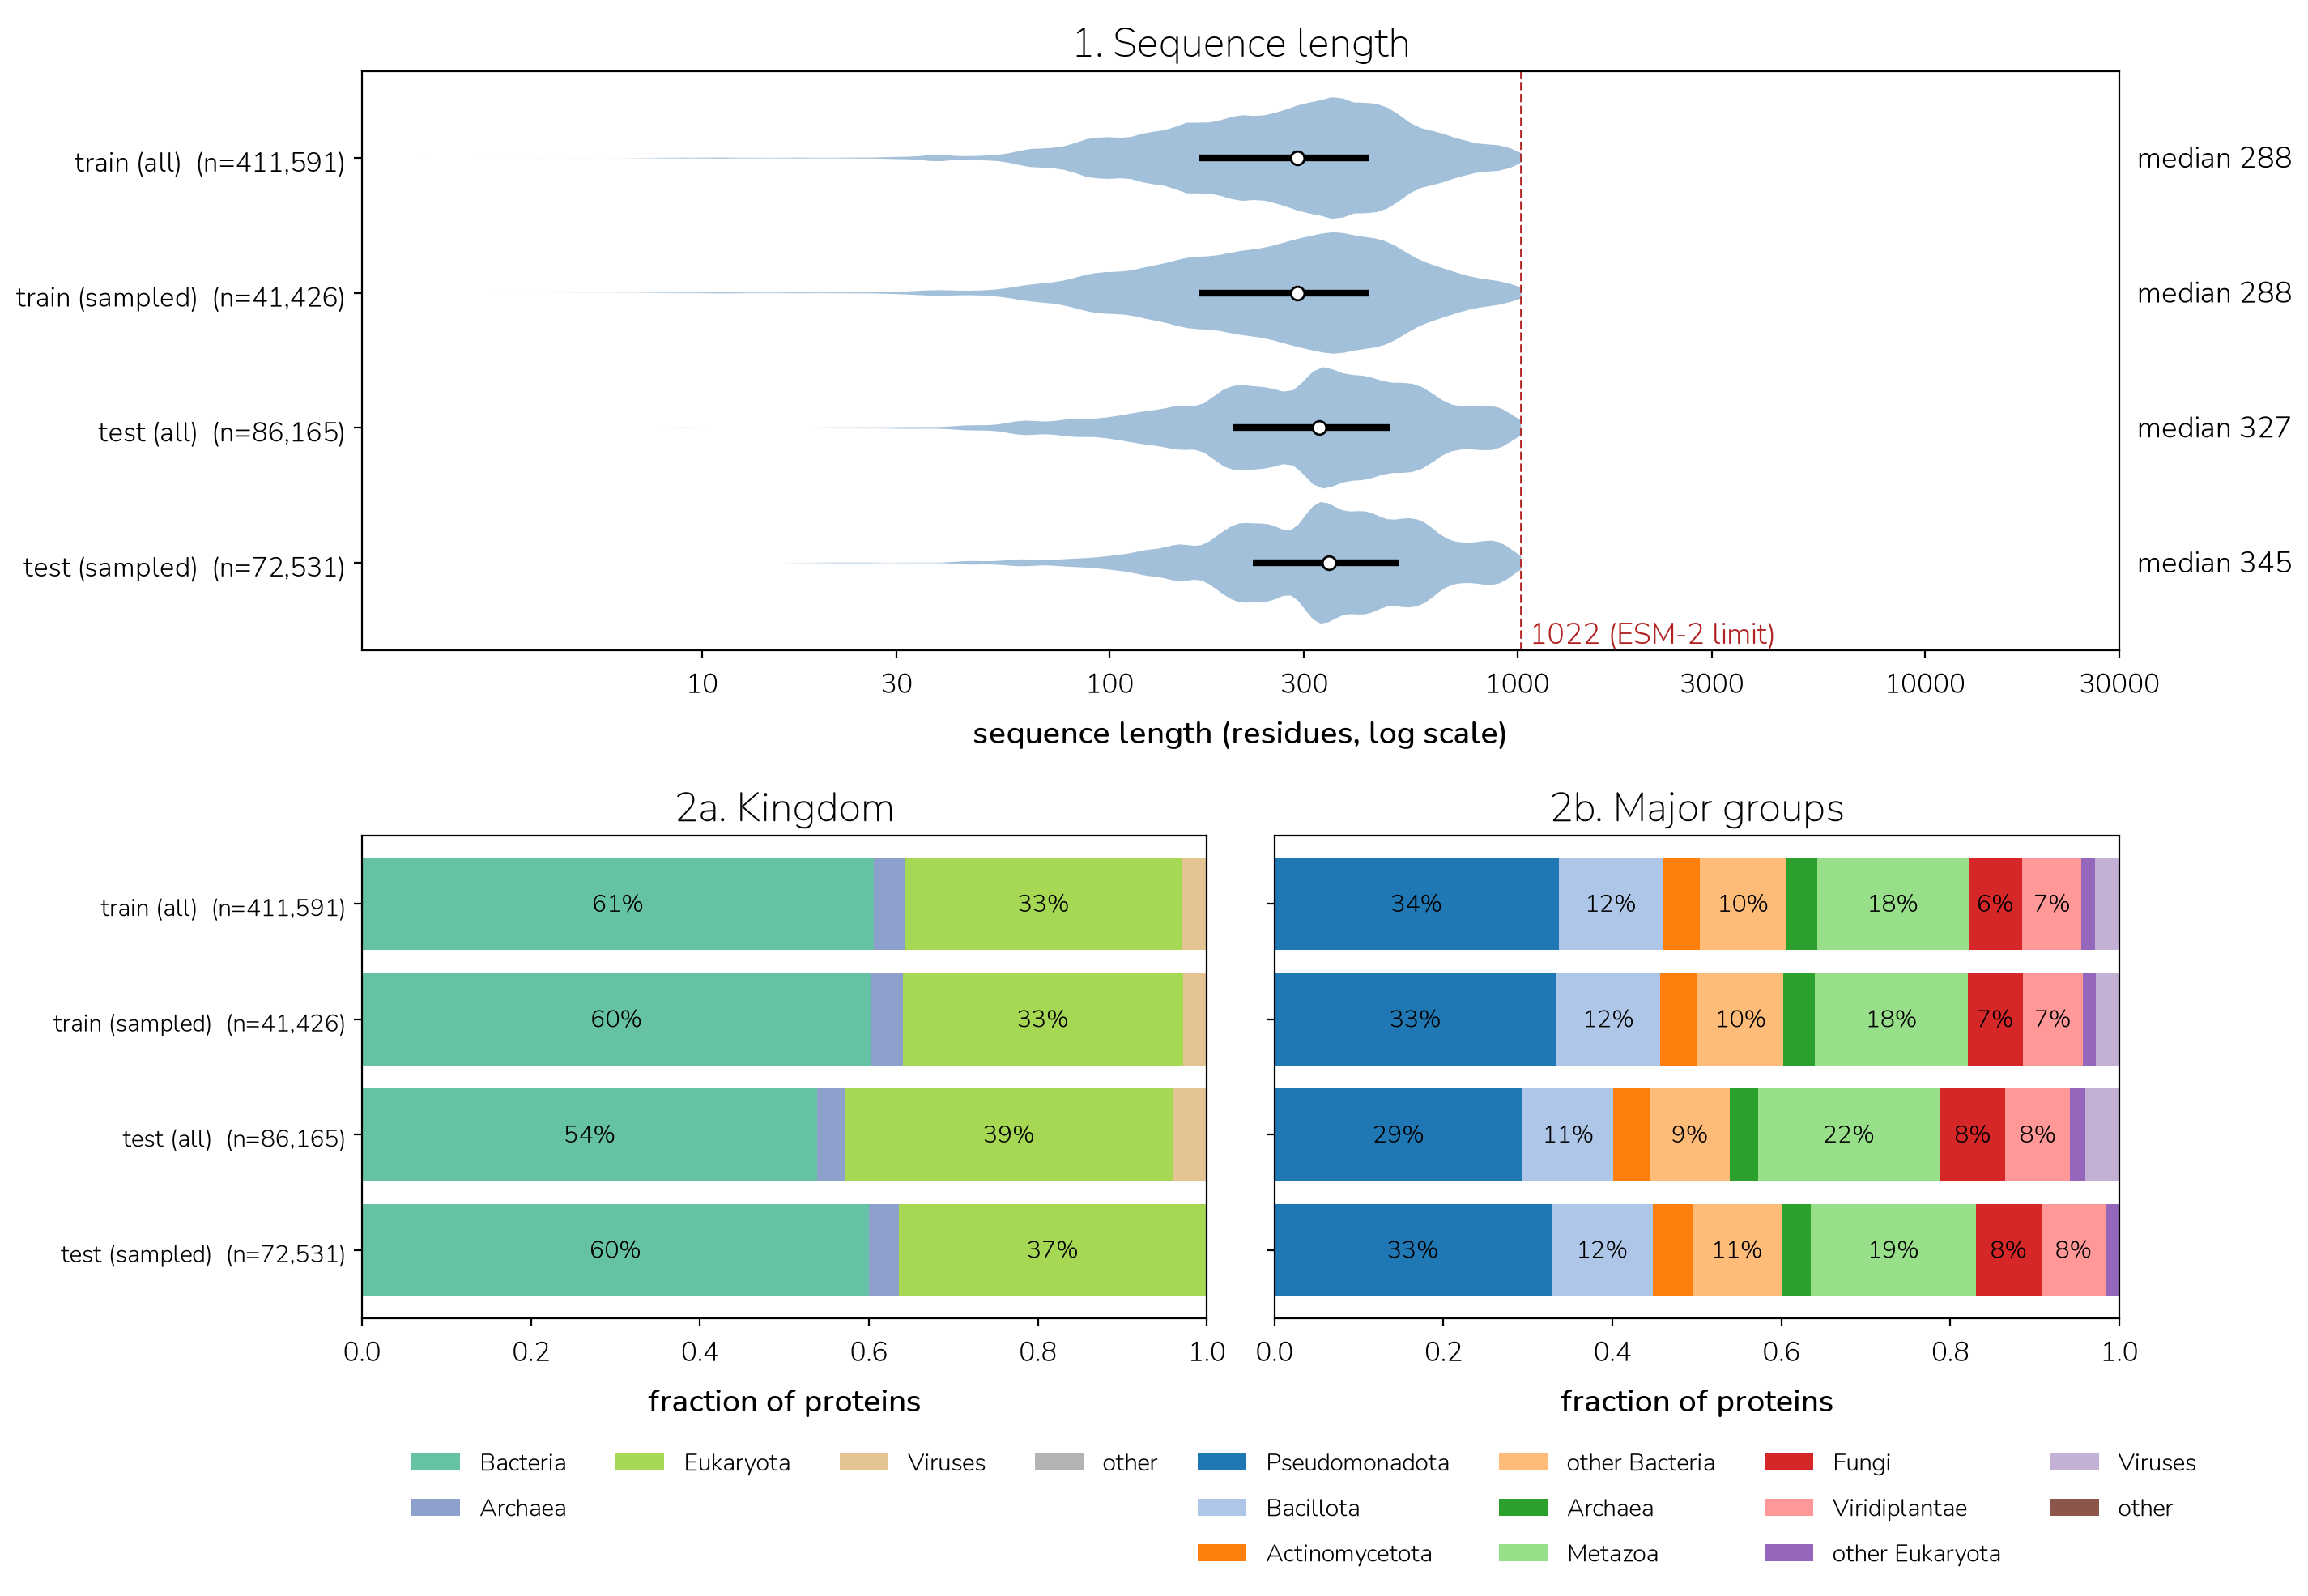

In [2]:
all_proteins = (
    sequence_labels.load_protein_labels()
    .join(swissprot_labels.load_protein_labels().select("accession", "kingdom", "group"), on="accession")
    .join(splits.lazy(), on="accession")
    .collect()
)
groups = {}
for split in SPLITS:
    everything = all_proteins.filter(pl.col("split") == split)
    sampled = everything.filter(pl.col("accession").is_in(proteins[split]["accession"].implode()))
    print(f"{split} sampled: {len(sampled):,} of {len(everything):,} proteins ({len(sampled) / len(everything):.1%}), "
          f"{len(rows[split]):,} of {everything['length'].sum():,} residues")
    groups[f"{split} (all)"], groups[f"{split} (sampled)"] = everything, sampled
plots.protein_summary(groups);

## Mean embeddings per label bin
For each label: take all residues that have a value, from 40k proteins sampled off the **train** split; group all residues into bins and compute the means for each bin, leaving out bins with fewer than 200 residues (as in the esm-interp dashboard). Visualize with 3D PCA, print variance explained from further PCs

The slider changes the bin width from 1-4, larger bin widths result in smoother-looking visualisations. 

In [3]:
MIN_COUNT = 200  # bins with fewer residues are left out

# sum and count of the embeddings per 1-unit bin, for each split, layer and label, saved so that they are only computed once
sums, counts = {}, {}
for split in SPLITS:
    bin_files = {layer: {name: config.data_path("label_bins") / f"{split}_{name}_L{layer}.npy" for name in [
        "helix_face_1deg_bin_sums", "helix_face_1deg_bin_counts", "plddt_1unit_bin_sums", "plddt_1unit_bin_counts"]}
        for layer in LAYERS}
    missing = [layer for layer in LAYERS if not all(path.exists() for path in bin_files[layer].values())]

    if missing:
        # helix face and pLDDT of every embedding row, in row order (null: no AFDB model, or no value).
        # The 171M-row label table is streamed on the left of the join, so that only the embedding
        # rows are held in memory.
        labels = (
            af2_structure_labels.load_labels(["accession", "i", "helix_face", "plddt"])
            .join(rows[split].with_row_index("row").lazy(), on=["accession", "i"])
            .collect(engine="streaming")
        )
        row_labels = pl.DataFrame({"row": np.arange(len(rows[split]), dtype=np.uint32)}).join(labels, on="row", how="left").sort("row")
        # bin of every row in 1-unit bins, -1 = no value
        #   helix face (-180, 180] degrees -> bins 0..359 (bin k: [k - 180, k - 179), 180 wraps to -180)
        #   pLDDT [0, 100] -> bins 0..100 (bin k: [k, k + 1))
        helix_bins = ((row_labels["helix_face"].floor() + 180) % 360).fill_null(-1).cast(pl.Int64).to_numpy()
        plddt_bins = row_labels["plddt"].floor().fill_null(-1).cast(pl.Int64).to_numpy()

    for layer in LAYERS:
        if layer in missing:
            # sum and count of the embeddings in every bin of width 1, reading the embeddings 1M rows at a time
            helix_sums, helix_counts = np.zeros((360, 640)), np.zeros(360)
            plddt_sums, plddt_counts = np.zeros((101, 640)), np.zeros(101)
            for start in range(0, len(embeddings[split, layer]), 1_000_000):
                x = embeddings[split, layer][start:start + 1_000_000].astype(np.float32)
                for bsums, bcounts, bins in [(helix_sums, helix_counts, helix_bins), (plddt_sums, plddt_counts, plddt_bins)]:
                    b = bins[start:start + 1_000_000]
                    for k in np.unique(b[b >= 0]):
                        bsums[k] += x[b == k].sum(0)
                        bcounts[k] += (b == k).sum()
            for path, array in zip(bin_files[layer].values(), [helix_sums, helix_counts, plddt_sums, plddt_counts]):
                np.save(path, array)
        else:
            helix_sums, helix_counts, plddt_sums, plddt_counts = (np.load(path) for path in bin_files[layer].values())
        sums[split, layer] = {"helix_face": helix_sums, "plddt": plddt_sums}
        counts[split, layer] = {"helix_face": helix_counts, "plddt": plddt_counts}

In [4]:
def bin_means(sums, counts, first_value, width):
    """Mean embedding per bin of `width` neighbouring 1-unit bins, for the bins with at least MIN_COUNT residues:
    means (bins, 640), label value at the centre of each bin, residues per bin, and a text about the dropped bins."""
    firsts = np.arange(0, len(counts), width)
    bin_sums, bin_counts = np.add.reduceat(sums, firsts), np.add.reduceat(counts, firsts)
    keep = bin_counts >= MIN_COUNT
    return {
        "means": bin_sums[keep] / bin_counts[keep, None],
        "centers": first_value + firsts[keep] + width / 2,
        "counts": bin_counts[keep],
        "dropped": f"{(bin_counts == 0).sum()} empty bins, {((bin_counts > 0) & ~keep).sum()} bins with fewer than {MIN_COUNT} residues",
    }


def pca_axes(means, reference=None):
    """PC axes of `means`: their centre, the first 6 components, and the fraction of variance each explains.
    With `reference` (the components of another fit), each PC is flipped to point the same way."""
    center = means.mean(0)
    _, s, vt = np.linalg.svd(means - center, full_matrices=False)
    components = vt[:6]
    if reference is not None:
        components = components * np.sign((components * reference).sum(1))[:, None]
    return {"center": center, "components": components, "explained": (s**2 / (s**2).sum())[:6]}

In [5]:
def plot_pca(points, axes, label, title, periodic=False):
    """3D plot of `points[layer, width]` (from bin_means) projected on `axes[layer, width]` (from pca_axes),
    with one slider for the layer and one for the bin width (ipywidgets: needs a running kernel)."""
    def draw(layer, width):
        p, a = points[layer, width], axes[layer, width]
        pcs = (p["means"] - a["center"]) @ a["components"][:3].T

        order = np.r_[np.arange(len(pcs)), 0] if periodic else np.arange(len(pcs))  # periodic: close the loop
        fig = go.Figure(go.Scatter3d(
            x=pcs[order, 0], y=pcs[order, 1], z=pcs[order, 2], mode="markers+lines",
            line=dict(color="lightgray"), hoverinfo="text",
            text=[f"{label} {p['centers'][j]:g}: {p['counts'][j]:,.0f} residues" for j in order],
            marker=dict(size=4, color=p["centers"][order], colorbar=dict(title=label),
                        colorscale="Twilight" if periodic else "Viridis",
                        cmin=-180 if periodic else None, cmax=180 if periodic else None),
        ))
        fig.add_annotation(text=f"dropped: {p['dropped']}", x=1, y=0, xref="paper", yref="paper", xanchor="right",
                           yanchor="bottom", showarrow=False, font=dict(size=11, color="gray"))
        axis_titles = {f"{x}axis_title": f"PC{k + 1} ({a['explained'][k]:.1%})" for k, x in enumerate("xyz")}
        fig.update_layout(height=650, title=f"Layer {layer}, bin width {width}: {title}", font=dict(family="Nunito, sans-serif"),
                          scene=dict(aspectmode="data", **axis_titles))  # aspectmode data: proportional axes
        fig.show()

    interact(draw, layer=SelectionSlider(options=sorted({layer for layer, _ in points}), description="layer"),
             width=SelectionSlider(options=sorted({width for _, width in points}), description="bin width"))

### Helix face

In [6]:
widths = [1, 2, 5, 10]
points, axes = {split: {} for split in SPLITS}, {}
for layer in LAYERS:
    for w in widths:
        key = (layer, w)
        for split in SPLITS:
            points[split][key] = bin_means(sums[split, layer]["helix_face"], counts[split, layer]["helix_face"], -180, w)
        # train PC axes, saved; the PC directions are aligned with the first bin width of the same layer
        reference = axes[layer, widths[0]]["components"] if w != widths[0] else None
        axes[key] = pca_axes(points["train"][key]["means"], reference)
        np.savez(config.data_path("label_bins") / f"train_helix_face_width{w}_pca_axes_L{layer}.npz", **axes[key])
        print(f"layer {layer}, bin width {w}: train PC1-6 explain {np.round(axes[key]['explained'], 3)}")

plot_pca(points["train"], axes, "helix_face", "<b>train</b> mean embedding per helix_face bin, on the train PCs", periodic=True)
plot_pca(points["test"], axes, "helix_face", "<b>test</b> mean embedding per helix_face bin, on the train PCs", periodic=True)

layer 18, bin width 1: train PC1-6 explain [0.64  0.233 0.013 0.008 0.007 0.005]
layer 18, bin width 2: train PC1-6 explain [0.658 0.24  0.013 0.007 0.007 0.005]
layer 18, bin width 5: train PC1-6 explain [0.676 0.246 0.013 0.007 0.006 0.005]
layer 18, bin width 10: train PC1-6 explain [0.689 0.251 0.013 0.007 0.006 0.005]
layer 28, bin width 1: train PC1-6 explain [0.707 0.25  0.018 0.008 0.001 0.001]
layer 28, bin width 2: train PC1-6 explain [0.71  0.251 0.018 0.008 0.001 0.001]
layer 28, bin width 5: train PC1-6 explain [0.713 0.252 0.018 0.008 0.001 0.001]
layer 28, bin width 10: train PC1-6 explain [0.715 0.252 0.018 0.008 0.001 0.001]
layer 30, bin width 1: train PC1-6 explain [0.806 0.155 0.016 0.007 0.002 0.001]
layer 30, bin width 2: train PC1-6 explain [0.809 0.156 0.016 0.007 0.001 0.001]
layer 30, bin width 5: train PC1-6 explain [0.813 0.156 0.016 0.007 0.001 0.001]
layer 30, bin width 10: train PC1-6 explain [0.815 0.157 0.016 0.007 0.001 0.001]


interactive(children=(SelectionSlider(description='layer', options=(18, 28, 30), value=18), SelectionSlider(de…

interactive(children=(SelectionSlider(description='layer', options=(18, 28, 30), value=18), SelectionSlider(de…

### pLDDT

In [7]:
widths = [1, 2, 5]
points, axes = {split: {} for split in SPLITS}, {}
for layer in LAYERS:
    for w in widths:
        key = (layer, w)
        for split in SPLITS:
            points[split][key] = bin_means(sums[split, layer]["plddt"], counts[split, layer]["plddt"], 0, w)
        # train PC axes, saved; the PC directions are aligned with the first bin width of the same layer
        reference = axes[layer, widths[0]]["components"] if w != widths[0] else None
        axes[key] = pca_axes(points["train"][key]["means"], reference)
        np.savez(config.data_path("label_bins") / f"train_plddt_width{w}_pca_axes_L{layer}.npz", **axes[key])
        print(f"layer {layer}, bin width {w}: train PC1-6 explain {np.round(axes[key]['explained'], 3)}")

plot_pca(points["train"], axes, "plddt", "<b>train</b> mean embedding per plddt bin, on the train PCs")
plot_pca(points["test"], axes, "plddt", "<b>test</b> mean embedding per plddt bin, on the train PCs")

layer 18, bin width 1: train PC1-6 explain [0.867 0.09  0.023 0.01  0.004 0.002]
layer 18, bin width 2: train PC1-6 explain [0.933 0.038 0.016 0.006 0.004 0.001]
layer 18, bin width 5: train PC1-6 explain [0.932 0.039 0.015 0.007 0.005 0.001]
layer 28, bin width 1: train PC1-6 explain [0.907 0.064 0.016 0.008 0.002 0.001]
layer 28, bin width 2: train PC1-6 explain [0.948 0.033 0.011 0.004 0.002 0.001]
layer 28, bin width 5: train PC1-6 explain [0.947 0.033 0.012 0.004 0.003 0.   ]
layer 30, bin width 1: train PC1-6 explain [0.879 0.088 0.018 0.009 0.003 0.002]
layer 30, bin width 2: train PC1-6 explain [0.927 0.046 0.017 0.005 0.003 0.001]
layer 30, bin width 5: train PC1-6 explain [0.924 0.045 0.019 0.008 0.003 0.001]


interactive(children=(SelectionSlider(description='layer', options=(18, 28, 30), value=18), SelectionSlider(de…

interactive(children=(SelectionSlider(description='layer', options=(18, 28, 30), value=18), SelectionSlider(de…